<a href="https://colab.research.google.com/github/fforster/alerce-iucaa-2026/blob/main/04_agn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 04 · AGN: multiwavelength crossmatches and spectroscopic redshifts

**ALeRCE multisurvey tutorial — IUCAA 2026** · ~30 min

Active galactic nuclei (AGN) are accreting supermassive black holes. In optical surveys they look like
point-like (quasars) or nuclear (Seyferts) sources whose brightness **varies stochastically** on all time scales.
Variability alone is a good AGN selector, but the classic confirmation is **multiwavelength**: AGN are bright in
X-rays and in the UV, and their hot dusty torus makes them red in the mid-infrared. A **spectroscopic redshift**
then turns fluxes into luminosities and observed time scales into rest-frame ones.

**Contents**
1. One quasar, two surveys: light curves and classifications
2. Crossmatches inside the database: AllWISE and Gaia DR3
3. Crossmatches outside the database: catsHTM and the experimental explorer
4. A rest-frame spectral energy distribution (SED) from X-rays to the mid-infrared
5. An AGN sample seen by ZTF and LSST
6. Mid-infrared colours, Gaia flags and redshifts of the sample
7. Variability features in both surveys
8. The rest-frame structure function from ZTF + LSST
9. Exercises

In [1]:
import sys

if "google.colab" in sys.modules:
    !pip -q install pyvo astroquery
    !wget -q -N https://raw.githubusercontent.com/fforster/alerce-iucaa-2026/main/alerce_ms.py
    !mkdir -p data
    !wget -q -N -P data https://raw.githubusercontent.com/fforster/alerce-iucaa-2026/main/data/agn_sample.csv
    !wget -q -N -P data https://raw.githubusercontent.com/fforster/alerce-iucaa-2026/main/data/agn_lightcurves.csv.gz

import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import astropy.units as u
from astropy.cosmology import Planck18

import alerce_ms as am

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

## 1. One quasar, two surveys

Our example is `ZTF20acyxpwi`, in the COSMOS field. As in notebook 02, we link it to LSST with a positional
cone search (there is no cross-survey association in the database):

In [2]:
qso_ztf = "ZTF20acyxpwi"
obj = am.get_object(qso_ztf, "ztf")
ra, dec = obj["meanra"], obj["meandec"]
print(f"RA = {ra:.6f}, Dec = {dec:.6f}")
am.find_counterparts(ra, dec, radius_arcsec=2)[["name", "survey", "sid", "oid", "sep_arcsec"]]

RA = 150.700525, Dec = 3.532180


,name,survey,sid,oid,sep_arcsec
0,ZTF20acyxpwi,ztf,0,36028957690312632,0.000000
1,313985345706262538,lsst,1,313985345706262538,0.439534


In [3]:
qso_lsst = 313985345706262538
lc = pd.concat([am.get_lightcurve(qso_ztf, 0), am.get_lightcurve(qso_lsst, 1)], ignore_index=True)
lc.groupby(["survey", "band_name"]).agg(n=("mjd", "size"), first=("mjd", "min"), last=("mjd", "max"),
                                        median_mag=("sci_mag", "median")).round(2)

n     first      last  median_mag
survey band_name                                     
lsst   g          412  61090.19  61204.98       18.07
       i          546  61090.11  61204.97       17.59
       r          380  61090.21  61205.98       17.76
       u           92  61054.15  61204.98       18.16
       y           40  61094.27  61198.00       17.59
       z          381  61090.20  61205.99       17.58
ztf    g           85  60052.23  60818.18       18.22
       r          135  60220.53  60816.24       17.83

For a variable point source we want the **total** brightness, not the difference with respect to a template
(the template already contains the quasar at some average flux). We therefore plot `sci_mag`: `magpsf_corr` /
`mag_corr` for ZTF and `scienceflux` for LSST.

A few forced-photometry points are obviously wrong (measurements on bad pixels or image edges, several magnitudes
fainter than the rest). We remove points more than 1 mag away from the median of their survey and band:

kept 2060 of 2071 points


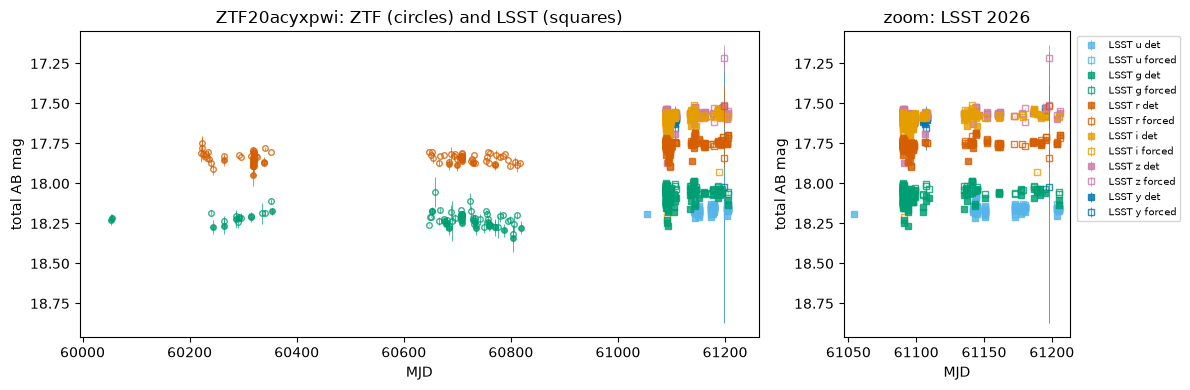

In [4]:
def clean_lightcurve(lc, max_dev=1.0):
    """Keep finite total magnitudes within max_dev mag of the median of each survey/band."""
    lc = lc[np.isfinite(lc.sci_mag)].copy()
    dev = lc.sci_mag - lc.groupby(["survey", "band_name"]).sci_mag.transform("median")
    return lc[dev.abs() < max_dev]


lc_clean = clean_lightcurve(lc)
print(f"kept {len(lc_clean)} of {len(lc)} points")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [3, 1]})
am.plot_lightcurve(lc_clean, flux="sci", mag=True, ax=axes[0])
axes[0].get_legend().remove()
am.plot_lightcurve(lc_clean[lc_clean.survey == "lsst"], flux="sci", mag=True, ax=axes[1])
axes[0].set_title(f"{qso_ztf}: ZTF (circles) and LSST (squares)")
axes[1].set_title("zoom: LSST 2026")
plt.tight_layout();

* The quasar varies by ~0.1–0.2 mag, smoothly and without a repeating pattern: **stochastic variability**, the
  hallmark of AGN. (Small offsets between the ZTF and LSST levels in the same band come from the different filters.)
* LSST samples the same source many times per night in six bands (COSMOS is a Rubin deep-drilling field).
  Together, ZTF and LSST cover more than three years.

### What do the classifiers say?

In [5]:
probs = pd.concat([am.get_probabilities(qso_ztf, 0), am.get_probabilities(qso_lsst, 1)])
probs.query("ranking <= 2")[["survey_name", "classifier_name", "class_name", "probability", "ranking"]]

,survey_name,classifier_name,class_name,probability,ranking
0,ZTF,lc_classifier_BHRF_forced_phot,QSO,0.831360,1
1,ZTF,lc_classifier_BHRF_forced_phot,AGN,0.061440,2
21,ZTF,lc_classifier_BHRF_forced_phot_periodic,Periodic-Other,0.270000,1
22,ZTF,lc_classifier_BHRF_forced_phot_periodic,RSCVn,0.230000,2
30,ZTF,lc_classifier_BHRF_forced_phot_stochastic,QSO,0.866000,1
31,ZTF,lc_classifier_BHRF_forced_phot_stochastic,AGN,0.064000,2
36,ZTF,lc_classifier_BHRF_forced_phot_top,Stochastic,0.960000,1
37,ZTF,lc_classifier_BHRF_forced_phot_top,Transient,0.036000,2
39,ZTF,lc_classifier_BHRF_forced_phot_transient,TDE,0.240000,1
40,ZTF,lc_classifier_BHRF_forced_phot_transient,SNII,0.206000,2


* ZTF light-curve classifier: **Stochastic** at the top level and **QSO** within the stochastic branch.
* ZTF stamp classifiers (first alert only): **AGN**.
* LSST stamp classifiers (first alert only): **VS** (variable star), with AGN as second choice. A single image
  of a point-like variable source cannot tell a quasar from a star. We need more information: colours,
  astrometry, a spectrum…

## 2. Crossmatches inside the database

The `xmatch` table links each object to AllWISE (mid-infrared, plus 2MASS near-infrared) and Gaia DR3.
`am.get_xmatch` joins `xmatch`, `catalog_id_lut`, `allwise` and `gaiadr3_source`:

In [6]:
xm = pd.concat([am.get_xmatch(qso_ztf, 0).assign(survey="ztf"),
                am.get_xmatch(qso_lsst, 1).assign(survey="lsst")])
xm.set_index(["survey", "catalog_name"]).T.dropna(how="all")

survey                                         ztf                  lsst                     
catalog_name                               AllWISE               AllWISE       GaiaDR3_source
oid_catalog                   1512p030_ac51-062173  1512p030_ac51-062173  3836874364905765248
dist                                      0.390874              0.041923             0.029281
w1mpro                                      14.489                14.489                  NaN
w2mpro                                      13.182                13.182                  NaN
w3mpro                                      10.004                10.004                  NaN
w4mpro                                        7.57                  7.57                  NaN
w1_w2                                        1.307                 1.307                  NaN
j_m_2mass                                   16.553                16.553                  NaN
h_m_2mass                                   15.633                15.633                  NaN
k_m_2mass                                   15.746                15.746                  NaN
phot_g_mean_mag                                NaN                   NaN            17.669119
bp_rp                                          NaN                   NaN             0.682604
parallax                                       NaN                   NaN            -0.706931
parallax_error                                 NaN                   NaN             0.245048
pm                                             NaN                   NaN             0.516961
ruwe                                           NaN                   NaN             1.207924
phot_variable_flag                                                                   VARIABLE
in_qso_candidates                              NaN                   NaN                 True
in_galaxy_candidates                           NaN                   NaN                False
classprob_dsc_combmod_quasar                   NaN                   NaN             0.998375
classprob_dsc_combmod_galaxy                   NaN                   NaN                  0.0
classprob_dsc_combmod_star                     NaN                   NaN                  0.0

Three independent hints that this is a quasar:

* **Mid-infrared colour** W1 − W2 = 1.31 mag (Vega). Stars have W1 − W2 ≈ 0; Stern et al. (2012) select AGN with
  W1 − W2 ≥ 0.8, because the hot dust of the torus makes AGN red at 3–5 µm.
* **Astrometry**: no significant positive parallax (−0.71 ± 0.25 mas) and a tiny proper motion (0.5 mas/yr):
  not what a nearby star of G ≈ 17.7 would show.
* **Gaia's own classification** puts it in the QSO candidate table with P(quasar) ≈ 1.

## 3. Crossmatches outside the database

### 3.1 catsHTM

ALeRCE runs a catsHTM service that returns the nearest source in ~15 catalogs: GALEX (UV), SDSS (optical
photometry *and spectra*), 2MASS / UKIDSS (near-IR), WISE / unWISE (mid-IR), XMM (X-rays), NED redshifts, Gaia…
The multisurvey API's `crossmatch_api` gives the same information for an `oid`.

In [7]:
cats = am.catshtm_crossmatch(ra, dec, radius_arcsec=5)
pd.DataFrame({cat: {"distance [arcsec]": d["distance"], "n columns": len(d) - 1}
              for cat, d in cats.items()}).T

,distance [arcsec],n columns
2MASS,0.379065,11.0
DECaLS,0.429262,27.0
GAIA/DR1,0.435363,9.0
GAIA/DR2,0.437780,28.0
GALEX,0.470949,10.0
NEDz,0.471445,9.0
SDSS/DR10,0.466975,17.0
SDSSoffset,0.467012,35.0
SpecSDSS,0.465336,33.0
UKIDSS,0.470853,39.0


Each entry is a dictionary of columns. For example the **SDSS spectrum** and the **NED redshift**:

In [8]:
spec = cats["SpecSDSS"]
print(f"SDSS spectrum: z = {spec['z']:.4f} ± {spec['zErr']:.4f}, zWarning = {spec['zWarning']:.0f}, "
      f"plate-MJD-fiber = {spec['plate']:.0f}-{spec['mjd']:.0f}-{spec['fiberID']:.0f}")
print(f"NED:           z = {cats['NEDz']['z']:.4f}")

SDSS spectrum: z = 1.4816 ± 0.0001, zWarning = 0, plate-MJD-fiber = 4737-55630-958
NED:           z = 1.4845


### ⚠️ Always check your data: the XMM coordinates

Look at the position of the XMM source:

In [9]:
xmm = cats["XMM"]
print("XMM RA, Dec =", xmm["RA"], xmm["DEC"], "  units claimed:", xmm["_units"]["RA"])
print("in degrees  =", np.degrees(xmm["RA"]), np.degrees(xmm["DEC"]))
print(f"X-ray flux (0.2–12 keV) = {xmm['EP_8_FLUX']:.2e} ± {xmm['EP_8_FLUX_ERR']:.2e} erg/s/cm²")

XMM RA, Dec = 2.6302253970291223 0.061653868657378576   units claimed: deg
in degrees  = 150.70081441789 3.5325064647217
X-ray flux (0.2–12 keV) = 9.90e-14 ± 2.08e-14 erg/s/cm²


The service says the units are degrees, but RA = 2.63 is obviously not our quasar at RA = 150.7. The values
are in **radians**: once converted, the XMM source sits on the quasar. Bugs like this exist in every archive; a
quick sanity check (does the position make sense?) saves you from wrong science.

### 3.2 The experimental explorer: redshifts from many surveys

The experimental explorer queries Simbad, NED, SDSS, DESI DR1, 2dF, 6dF, GAMA, Milliquas, VSX, Gaia, … around an
object and returns a summary with `category` = `stellar`, `agn` or `host`. `am.explorer_xmatch` calls it:

In [10]:
ex = am.explorer_xmatch(qso_ztf, "ztf")
ex[ex.sep < 3]

,cat_name,category,name,type,z,z_err,sep,ra,dec
0,NED,host,WISEA J100248.15+033155.9,QSO,1.481770,0.000065,0.389278,150.700629,3.532209
1,Gaia DR3,stellar,3836874364905765248,variable star,NaN,NaN,0.437613,150.700638,3.532225
2,DESI,host,DESI J150.7006+03.5322,QSO,1.482894,0.000073,0.437677,150.700638,3.532225
3,DESI,host,DESI J150.7006+03.5322,QSO,1.483213,0.000149,0.437677,150.700638,3.532225
4,DESI,host,DESI J150.7006+03.5322,QSO,1.482986,0.000097,0.437677,150.700638,3.532225
5,Milliquas,agn,SDSS J100248.15+033155.9,QSO,1.482000,NaN,0.437985,150.700638,3.532225
6,Simbad,agn,[VV2006] J100248.2+033156,QSO,1.483400,0.005000,0.442076,150.700640,3.532224
7,SDSS DR16 QSO,agn,SDSS DR16 QSO J100248.2+033156.0,30,1.482000,NaN,0.466334,150.700649,3.532219
8,Veron-Cetty,agn,SDSS J10028+0331,QSO,1.481000,NaN,1.116771,150.700833,3.532222


Several independent spectroscopic redshifts agree: a quasar at **z ≈ 1.48**.

In [11]:
z_qso = spec["z"]
print(f"lookback time = {Planck18.lookback_time(z_qso):.2f}, "
      f"luminosity distance = {Planck18.luminosity_distance(z_qso):.0f}")

lookback time = 9.47 Gyr, luminosity distance = 11025 Mpc


## 4. A rest-frame SED

With the catsHTM photometry and the redshift we can build the spectral energy distribution (SED) of the quasar.
Recipe:

1. Convert every magnitude to the **AB** system. SDSS and GALEX are already AB; 2MASS and WISE are **Vega**
   magnitudes and need offsets $m_{AB} = m_{Vega} + \Delta$ (2MASS: J 0.91, H 1.39, Ks 1.85; WISE: W1 2.699,
   W2 3.339, W3 5.174, W4 6.620).
2. $F_\nu = 3631\,\mathrm{Jy}\times10^{-0.4\,m_{AB}}$, at the filter's effective wavelength.
3. $\nu L_\nu = 4\pi d_L^2\,\nu F_\nu$ and $\lambda_{rest} = \lambda_{obs}/(1+z)$.

In [12]:
FILTERS = [  # (catalog, magnitude column, error column, band, effective wavelength [Å], AB - Vega offset)
    ("GALEX", "nuv_mag", "nuv_magerr", "NUV", 2271, 0.0),
    ("SDSS/DR10", "modelMag_u", "modelMagErr_u", "u", 3551, 0.0),
    ("SDSS/DR10", "modelMag_g", "modelMagErr_g", "g", 4686, 0.0),
    ("SDSS/DR10", "modelMag_r", "modelMagErr_r", "r", 6166, 0.0),
    ("SDSS/DR10", "modelMag_i", "modelMagErr_i", "i", 7480, 0.0),
    ("SDSS/DR10", "modelMag_z", "modelMagErr_z", "z", 8932, 0.0),
    ("2MASS", "Mag_J", "MagErr_J", "J", 12350, 0.91),
    ("2MASS", "Mag_H", "MagErr_H", "H", 16620, 1.39),
    ("2MASS", "Mag_K", "MagErr_K", "Ks", 21590, 1.85),
    ("WISE", "Mag_W1", "MagErr_W1", "W1", 33680, 2.699),
    ("WISE", "Mag_W2", "MagErr_W2", "W2", 46180, 3.339),
    ("WISE", "Mag_W3", "MagErr_W3", "W3", 120820, 5.174),
    ("WISE", "Mag_W4", "MagErr_W4", "W4", 221940, 6.620),
]
C_ANGSTROM = 2.998e18  # speed of light in Å/s


def catshtm_sed(cats, z):
    """Rest-frame SED (nu L_nu) from a catshtm_crossmatch() result."""
    rows = []
    for cat, col, ecol, band, lam, offset in FILTERS:
        value = cats.get(cat, {}).get(col)
        if value is not None and value > 0:
            rows.append(dict(catalog=cat, band=band, lam_obs=lam, mag_ab=value + offset,
                             mag_err=cats[cat][ecol]))
    sed = pd.DataFrame(rows)
    d_l = Planck18.luminosity_distance(z).to(u.cm).value
    sed["nu_obs"] = C_ANGSTROM / sed.lam_obs
    sed["fnu"] = 3631e-23 * 10 ** (-0.4 * sed.mag_ab)            # erg/s/cm²/Hz
    sed["nuLnu"] = 4 * np.pi * d_l ** 2 * sed.nu_obs * sed.fnu      # erg/s
    sed["nuLnu_err"] = sed.nuLnu * 0.4 * np.log(10) * sed.mag_err
    sed["lam_rest_um"] = sed.lam_obs / (1 + z) / 1e4
    return sed


sed = catshtm_sed(cats, z_qso)
sed.assign(fnu_mJy=sed.fnu / 1e-26)[["catalog", "band", "lam_obs", "mag_ab", "fnu_mJy", "lam_rest_um", "nuLnu"]]

,catalog,band,lam_obs,mag_ab,fnu_mJy,lam_rest_um,nuLnu
0,GALEX,NUV,2271,19.05161,0.086973,0.091512,1.669734e+46
1,SDSS/DR10,u,3551,18.30317,0.173284,0.143090,2.127599e+46
2,SDSS/DR10,g,4686,17.93670,0.242855,0.188826,2.259571e+46
3,SDSS/DR10,r,6166,17.74446,0.289896,0.248464,2.049844e+46
4,SDSS/DR10,i,7480,17.54549,0.348201,0.301413,2.029601e+46
5,SDSS/DR10,z,8932,17.55606,0.344828,0.359922,1.683200e+46
6,2MASS,J,12350,17.46300,0.375687,0.497653,1.326299e+46
7,2MASS,H,16620,17.02300,0.563412,0.669716,1.478010e+46
8,2MASS,Ks,21590,17.59600,0.332373,0.869986,6.712058e+45
9,WISE,W1,33680,17.14900,0.501679,1.357163,6.494359e+45


We add the LSST photometry (median `scienceflux` per band, 2026) and the X-ray point. XMM gives the flux integrated
over 0.2–12 keV; assuming the typical AGN power law $F_\nu\propto\nu^{-0.9}$ (photon index Γ = 1.9) we can compute
the flux density at any energy, e.g. at rest-frame 2 keV.

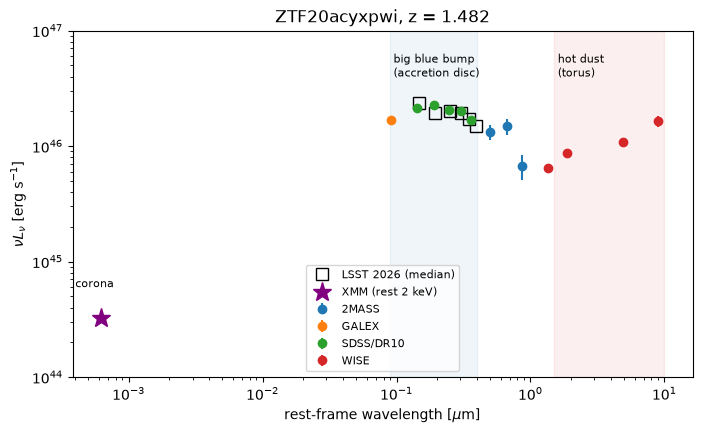

In [13]:
LSST_LAM = {"u": 3671, "g": 4827, "r": 6223, "i": 7546, "z": 8691, "y": 9712}  # effective wavelengths [Å]
d_l = Planck18.luminosity_distance(z_qso).to(u.cm).value

lsst_sed = lc_clean[lc_clean.survey == "lsst"].groupby("band_name").sci_flux.median().rename("flux_njy").reset_index()
lsst_sed["lam_obs"] = lsst_sed.band_name.map(LSST_LAM)
lsst_sed["fnu"] = lsst_sed.flux_njy * 1e-9 * 1e-23                       # nJy -> erg/s/cm²/Hz
lsst_sed["nuLnu"] = 4 * np.pi * d_l ** 2 * C_ANGSTROM / lsst_sed.lam_obs * lsst_sed.fnu
lsst_sed["lam_rest_um"] = lsst_sed.lam_obs / (1 + z_qso) / 1e4

KEV_HZ = 2.418e17                       # 1 keV in Hz
alpha_x = 0.9                           # F_nu ∝ nu^-alpha_x
nu1, nu2 = 0.2 * KEV_HZ, 12 * KEV_HZ
norm = xmm["EP_8_FLUX"] * (1 - alpha_x) / (nu2 ** (1 - alpha_x) - nu1 ** (1 - alpha_x))
nu_obs_2kev = 2 * KEV_HZ / (1 + z_qso)  # observed frequency of rest-frame 2 keV
fnu_2kev = norm * nu_obs_2kev ** -alpha_x
nuLnu_2kev = 4 * np.pi * d_l ** 2 * nu_obs_2kev * fnu_2kev
lam_rest_2kev_um = C_ANGSTROM / (2 * KEV_HZ) / 1e4

fig, ax = plt.subplots(figsize=(8, 4.5))
for cat, g in sed.groupby("catalog"):
    ax.errorbar(g.lam_rest_um, g.nuLnu, g.nuLnu_err, fmt="o", label=cat)
ax.plot(lsst_sed.lam_rest_um, lsst_sed.nuLnu, "s", mfc="none", ms=8, color="k", label="LSST 2026 (median)")
ax.plot(lam_rest_2kev_um, nuLnu_2kev, "*", ms=14, color="purple", label="XMM (rest 2 keV)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"rest-frame wavelength [$\mu$m]")
ax.set_ylabel(r"$\nu L_\nu$ [erg s$^{-1}$]")
ax.set_title(f"{qso_ztf}, z = {z_qso:.3f}")
ax.set_ylim(1e44, 1e47)
ax.axvspan(0.09, 0.4, color="tab:blue", alpha=0.07)
ax.text(0.095, 4e46, "big blue bump\n(accretion disc)", fontsize=8)
ax.axvspan(1.5, 10, color="tab:red", alpha=0.07)
ax.text(1.6, 4e46, "hot dust\n(torus)", fontsize=8)
ax.text(4e-4, 6e44, "corona", fontsize=8)
ax.legend(fontsize=8, loc="lower center");

The textbook quasar SED:

* $\nu L_\nu \approx 2\times10^{46}$ erg/s in the rest-frame UV: the **big blue bump**, thermal emission of the
  accretion disc;
* a minimum near 1 µm rest frame and a rise again beyond ~2 µm: **hot dust** in the torus, which is why
  W1 − W2 is red;
* the X-rays (hot corona) are much fainter than the disc in $\nu L_\nu$.

The **optical-to-X-ray index** $\alpha_{ox} = 0.3838\,\log_{10}[L_\nu(2\,\mathrm{keV}) / L_\nu(2500\,Å)]$
compares corona and disc. Rest-frame 2500 Å is observed at 2500 × (1 + z) ≈ 6200 Å, i.e. in the SDSS r band:

In [14]:
fnu_2500 = sed.set_index("band").loc["r", "fnu"]
alpha_ox = 0.3838 * np.log10(fnu_2kev / fnu_2500)       # the (1+z) factors cancel in the ratio
L2500 = 4 * np.pi * d_l ** 2 * fnu_2500 / (1 + z_qso)   # erg/s/Hz, rest frame
print(f"L_nu(2500 Å) = {L2500:.2e} erg/s/Hz,  alpha_ox = {alpha_ox:.2f}")
print(f"expected from the alpha_ox–L2500 relation of Just et al. (2007): {-0.140 * np.log10(L2500) + 2.705:.2f}")

L_nu(2500 Å) = 1.70e+31 erg/s/Hz,  alpha_ox = -1.69
expected from the alpha_ox–L2500 relation of Just et al. (2007): -1.67


A perfectly normal luminous quasar: its X-ray emission is what its UV luminosity predicts.

## 5. An AGN sample seen by ZTF and LSST

Now we scale up. We build a sample of AGN observed by **both** surveys, selected in two complementary ways:

* **A. ZTF-selected**: objects whose top class in the ZTF light-curve classifier's stochastic branch
  (`lc_classifier_BHRF_forced_phot_stochastic`) is QSO, AGN or Blazar, that have an LSST counterpart;
* **B. LSST-selected**: LSST objects whose top class in the newest Rubin stamp classifier is AGN (all in the
  COSMOS deep-drilling field), with their ZTF counterpart when there is one.

The recipe is below. Building the sample means a few hundred API calls (the LSST footprint overlaps only part of
the ZTF sky, so most ZTF candidates have no LSST counterpart yet). With a whole classroom on one IP address that
would trigger the server's rate limit, so by default we **load the result** from `data/agn_sample.csv`. Set
`REBUILD = True` at home to run it yourself (~20 min).

> Why not do the crossmatch in a single TAP query, uploading the candidate list and joining with `object`?
> We tried: a spatial join of a few hundred positions against the 150-million-row `object` table times out.
> For small lists, a loop over the API cone search is the practical way.

In [15]:
REBUILD = False
STAMP = "stamp_classifier_rubin_beta_20260421"
LC_STOCHASTIC = "lc_classifier_BHRF_forced_phot_stochastic"


def ztf_agn_with_lsst(classes=("QSO", "AGN", "Blazar"), pages=3, max_dec=15):
    """Set A: ZTF light-curve AGN candidates that have an LSST counterpart within 1.5 arcsec."""
    cands = []
    for cls in classes:
        for page in range(1, pages + 1):
            d = am.api_get("object", "list_objects", survey="ztf", classifier=LC_STOCHASTIC, class_name=cls,
                           probability=0.5, n_det=[50, 100000], page=page, page_size=100)
            cands += d["items"]
            time.sleep(1)
    cands = pd.DataFrame(cands).drop_duplicates("oid")
    cands = cands[cands.meandec < max_dec]          # LSST is a southern survey
    rows = []
    for c in cands.itertuples():
        m = am.find_counterparts(c.meanra, c.meandec, 1.5)
        m = m[m.survey == "lsst"]
        if len(m):
            rows.append(dict(name=c.oid, ztf_oid=am.ztf_name_to_oid(c.oid), lsst_oid=m.oid.iloc[0],
                             ra=c.meanra, dec=c.meandec, selected_by="ZTF light-curve classifier",
                             selection_class=c.class_name, selection_prob=c.probability))
        time.sleep(1.2)
    return pd.DataFrame(rows)


def lsst_agn_with_ztf(n=20):
    """Set B: top LSST stamp-classifier AGN candidates, with their ZTF counterpart if any."""
    d = am.api_get("object", "list_objects", survey="lsst", classifier=STAMP, class_name="AGN",
                   probability=0.8, n_det=[100, 100000], page_size=n)
    rows = []
    for c in d["items"]:
        m = am.find_counterparts(c["meanra"], c["meandec"], 1.5)
        m = m[m.survey == "ztf"]
        rows.append(dict(name=str(c["oid"]), ztf_oid=m.oid.iloc[0] if len(m) else pd.NA, lsst_oid=c["oid"],
                         ra=c["meanra"], dec=c["meandec"], selected_by="LSST stamp classifier",
                         selection_class="AGN", selection_prob=c["probability"]))
        time.sleep(1.2)
    return pd.DataFrame(rows)


if REBUILD:
    sample = pd.concat([ztf_agn_with_lsst(), lsst_agn_with_ztf()], ignore_index=True)
else:
    sample = pd.read_csv("data/agn_sample.csv")
sample["ztf_oid"] = sample.ztf_oid.astype("Int64")
print(sample.selected_by.value_counts().to_string())
sample.head()

selected_by
LSST stamp classifier         27
ZTF light-curve classifier    13


,name,ztf_oid,lsst_oid,ra,dec,selected_by,selection_class,selection_prob,z_spec,z_source,z_type
0,ZTF20aavijyr,36028957664911320,170534286223999391,240.741563,-17.773681,ZTF light-curve classifier,AGN,0.852,0.099931,NED,G
1,ZTF18abtimdn,36028941612259864,170591519550473337,304.100144,-9.059285,ZTF light-curve classifier,Blazar,0.696,0.605000,NED,QSO
2,ZTF23abtwsnv,36028981771561136,170591523036987780,321.160697,-16.143790,ZTF light-curve classifier,Blazar,0.720,0.400000,Milliquas,R
3,ZTF18abtfdff,36028941612201096,170587107536928921,336.992174,0.618195,ZTF light-curve classifier,Blazar,0.752,1.625639,DESI,GALAXY
4,ZTF19aadevks,36028949624813016,170046091675828358,149.872795,3.183784,ZTF light-curve classifier,AGN,0.844,0.124736,DESI,QSO


In [16]:
print("LSST-selected objects with a ZTF counterpart:",
      sample[sample.selected_by == "LSST stamp classifier"].ztf_oid.notna().sum())

LSST-selected objects with a ZTF counterpart: 1


Only one of the LSST-selected quasars has a ZTF counterpart: most are fainter than ZTF's limit (r ≈ 20.5).
Where are they on the sky?

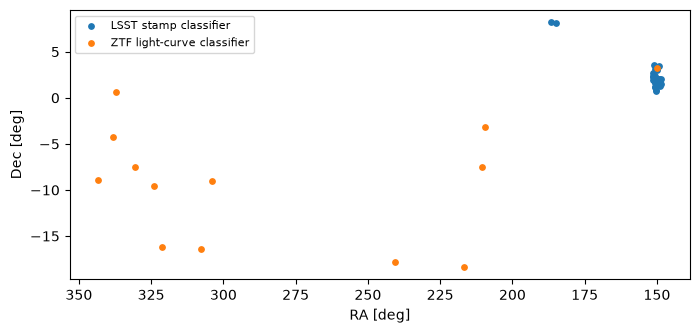

In [17]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for label, g in sample.groupby("selected_by"):
    ax.scatter(g.ra, g.dec, s=15, label=label)
ax.set_xlabel("RA [deg]")
ax.set_ylabel("Dec [deg]")
ax.invert_xaxis()
ax.legend(fontsize=8);

## 6. Mid-infrared colours, Gaia flags and redshifts

### 6.1 One TAP query for the whole sample

Instead of one query per object we send **one** query with an `IN (...)` list. We use the LSST `oid` of every
object (`sid = 1`), since all of them have one:

In [18]:
lsst_list = ", ".join(str(o) for o in sample.lsst_oid)
xm_all = am.tap_query(f"""
    SELECT x.oid AS lsst_oid, x.catid, x.dist,
           a.w1mpro, a.w2mpro, a.w3mpro, a.w4mpro,
           g.phot_g_mean_mag, g.parallax, g.parallax_error, g.pm,
           g.in_qso_candidates, g.in_galaxy_candidates, g.classprob_dsc_combmod_quasar
    FROM alerce_tap.xmatch AS x
    LEFT JOIN alerce_tap.allwise AS a ON x.catid = 0 AND a.oid_catalog = x.oid_catalog
    LEFT JOIN alerce_tap.gaiadr3_source AS g ON x.catid = 1 AND g.oid_catalog = x.oid_catalog
    WHERE x.sid = 1 AND x.oid IN ({lsst_list})
""")
wise = xm_all[xm_all.catid == 0][["lsst_oid", "w1mpro", "w2mpro", "w3mpro", "w4mpro"]]
gaia = xm_all[xm_all.catid == 1][["lsst_oid", "phot_g_mean_mag", "parallax", "parallax_error", "pm",
                                  "in_qso_candidates", "in_galaxy_candidates", "classprob_dsc_combmod_quasar"]]
sample = sample.merge(wise, on="lsst_oid", how="left").merge(gaia, on="lsst_oid", how="left")
sample["w1_w2"] = sample.w1mpro - sample.w2mpro
sample["w2_w3"] = sample.w2mpro - sample.w3mpro
print(f"{sample.w1mpro.notna().sum()} of {len(sample)} have AllWISE, {sample.phot_g_mean_mag.notna().sum()} have Gaia DR3")

24 of 40 have AllWISE, 16 have Gaia DR3


### 6.2 The WISE colour–colour diagram

Two classic mid-infrared AGN selections: W1 − W2 ≥ 0.8 (Stern et al. 2012) and the "AGN box" of Jarrett et al.
(2011): 2.2 < W2 − W3 < 4.2 and 0.1 (W2 − W3) + 0.38 < W1 − W2 < 1.7.

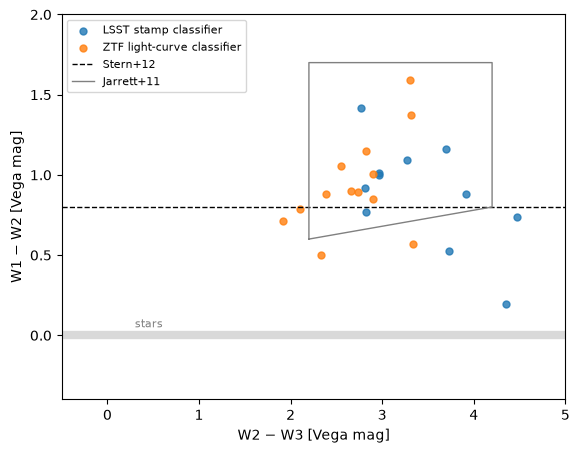

In [19]:
fig, ax = plt.subplots(figsize=(6.5, 5))
for label, g in sample.groupby("selected_by"):
    ax.scatter(g.w2_w3, g.w1_w2, s=25, label=label, alpha=0.8)
ax.axhline(0.8, color="k", ls="--", lw=1, label="Stern+12")
box_x = np.array([2.2, 2.2, 4.2, 4.2, 2.2])
box_y = np.array([0.1 * 2.2 + 0.38, 1.7, 1.7, 0.1 * 4.2 + 0.38, 0.1 * 2.2 + 0.38])
ax.plot(box_x, box_y, color="gray", lw=1, label="Jarrett+11")
ax.axhline(0.0, color="0.85", lw=6, zorder=0)
ax.text(0.3, 0.05, "stars", color="0.5", fontsize=8)
ax.set_xlabel("W2 − W3 [Vega mag]")
ax.set_ylabel("W1 − W2 [Vega mag]")
ax.set_xlim(-0.5, 5)
ax.set_ylim(-0.4, 2.0)
ax.legend(fontsize=8);

In [20]:
agn_wise = sample.w1_w2 >= 0.8
print(f"W1-W2 >= 0.8: {agn_wise.sum()} of {sample.w1_w2.notna().sum()} with WISE photometry")
print("Gaia QSO candidates:", int(sample.in_qso_candidates.fillna(False).astype(bool).sum()),
      "of", sample.phot_g_mean_mag.notna().sum(), "with Gaia")
sample.groupby("selected_by")[["w1_w2"]].describe().round(2)

W1-W2 >= 0.8: 16 of 24 with WISE photometry
Gaia QSO candidates: 13 of 16 with Gaia


w1_w2                                         
                           count  mean   std  min   25%   50%   75%   max
selected_by                                                              
LSST stamp classifier       11.0  0.88  0.33  0.2  0.75  0.92  1.05  1.42
ZTF light-curve classifier  13.0  0.94  0.30  0.5  0.79  0.89  1.06  1.59

* Two thirds of the objects with AllWISE photometry (16 of 24) pass the Stern et al. cut, and most sit in or near
  the Jarrett box, far from the stars at W1 − W2 ≈ 0.
* Of the ZTF-selected objects that fail it, three are classified as **blazars** (their mid-IR emission is
  non-thermal synchrotron, not torus dust) and one is a low-redshift Seyfert whose host galaxy dilutes the AGN colour.
* Many LSST-selected quasars have no AllWISE (or Gaia) match at all: they are faint (median r ≈ 22) and below the
  AllWISE and Gaia detection limits. LSST goes deeper than the all-sky catalogs we use to confirm AGN.
* All 13 ZTF-selected objects with a Gaia match are in Gaia's QSO candidate table.

### 6.3 Spectroscopic redshifts

For each object we ask the experimental explorer for spectroscopic redshifts within 2″ and keep the best one,
in order of preference DESI → SDSS → NED → Milliquas → Simbad → others. (Note: the explorer's `category` column
says in which panel it draws a source; the nature of the source is in `type`.)

In [21]:
PRIORITY = ["DESI", "SDSS DR16 QSO", "SDSS", "NED", "Milliquas", "Simbad", "6dFGS", "2dFGRS", "GAMA", "zCOSMOS"]


def best_specz(ex, max_sep=2.0):
    """(z, catalog, type) of the preferred spectroscopic redshift in an explorer_xmatch() table."""
    if ex.empty:                                   # nothing at all around this position
        return np.nan, "", ""
    ex = ex[(ex.sep < max_sep) & ex.z.notna()].copy()
    if ex.empty:
        return np.nan, "", ""
    ex["rank"] = [PRIORITY.index(c) if c in PRIORITY else len(PRIORITY) for c in ex.cat_name]
    best = ex.sort_values(["rank", "sep"]).iloc[0]
    return float(best.z), best.cat_name, str(best.type)


# live demo for the first three objects (~10 s each)
for row in sample.head(3).itertuples():
    print(row.name, best_specz(am.explorer_xmatch(int(row.lsst_oid), "lsst")))

ZTF20aavijyr (0.099931, 'NED', 'G')
ZTF18abtimdn (0.605, 'NED', 'QSO')
ZTF23abtwsnv (0.4000000059604645, 'Milliquas', 'R')


The redshifts of the full sample were computed the same way and stored in the columns `z_spec`, `z_source`
and `z_type` of `data/agn_sample.csv`:

36 of 40 objects have a spectroscopic redshift
z_source
DESI             29
NED               3
Simbad            2
Milliquas         1
SDSS DR16 QSO     1


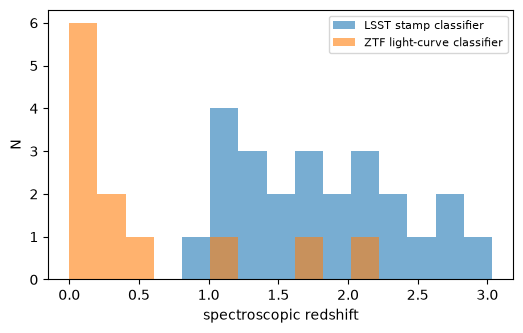

In [22]:
print(f"{sample.z_spec.notna().sum()} of {len(sample)} objects have a spectroscopic redshift")
print(sample.z_source.replace("", "none").value_counts().to_string())

fig, ax = plt.subplots(figsize=(6, 3.5))
bins = np.linspace(0, sample.z_spec.max() + 0.2, 16)
for label, g in sample.groupby("selected_by"):
    ax.hist(g.z_spec.dropna(), bins=bins, alpha=0.6, label=label)
ax.set_xlabel("spectroscopic redshift")
ax.set_ylabel("N")
ax.legend(fontsize=8);

The two selections probe very different populations:

* **LSST-selected** (COSMOS): faint quasars at z ≈ 0.9–2.8 (median 1.75), almost all with DESI spectra.
* **ZTF-selected**: brighter objects, mostly at z < 0.7 (median 0.24). For several low-redshift Seyferts the
  redshift comes from a spectrum classified as a **galaxy** (`z_type` = G / GALAXY): it is the host galaxy's
  redshift, which is of course also the AGN's.

### 6.4 Luminosities

With $z$ we compute the absolute magnitude in the r band from the median total magnitude (LSST when it has at least
10 r-band points, otherwise ZTF), with a K-correction for a power-law quasar continuum $F_\nu\propto\nu^{-0.5}$:
$M_r = m_r - DM(z) + 1.25\log_{10}(1+z)$.

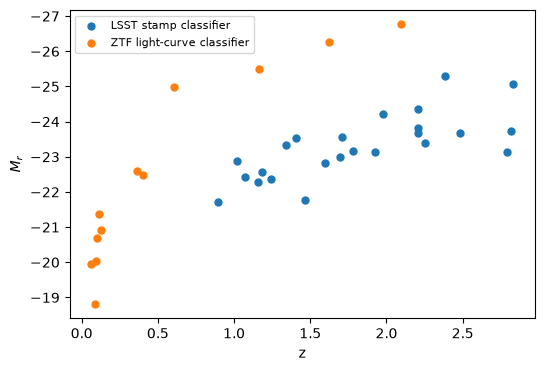

In [23]:
lcs = pd.read_csv("data/agn_lightcurves.csv.gz")
r_band = lcs[lcs.band == "r"].groupby(["name", "survey"]).mag.agg(["median", "size"]).unstack()
m_r = r_band["median"]["lsst"].where(r_band["size"]["lsst"] >= 10, r_band["median"].get("ztf"))
sample["m_r"] = sample.name.map(m_r)
has_z = sample.z_spec > 0
sample.loc[has_z, "M_r"] = (sample.m_r[has_z] - Planck18.distmod(sample.z_spec[has_z].values).value
                            + 1.25 * np.log10(1 + sample.z_spec[has_z]))

fig, ax = plt.subplots(figsize=(6, 4))
for label, g in sample.groupby("selected_by"):
    ax.scatter(g.z_spec, g.M_r, s=25, label=label)
ax.invert_yaxis()
ax.set_xlabel("z")
ax.set_ylabel("$M_r$")
ax.legend(fontsize=8);

The ZTF-selected AGN are either nearby, low-luminosity Seyferts ($M_r > -23$) or rare, very luminous quasars and
blazars; the deep LSST field reveals the far more numerous moderate-luminosity quasars at z ≈ 1–3.
(For the nearby objects the total magnitude includes the host galaxy, so $M_r$ overestimates the AGN's own luminosity.)

## 7. Variability features: read the fine print

ALeRCE computes variability features for every object and band, e.g. `Amplitude` and the parameters of a
damped-random-walk (DRW) fit: `GP_DRW_sigma` and `GP_DRW_tau`, the characteristic time scale in days. For AGN,
τ is expected to be weeks to years in the rest frame. One query per survey for the whole sample:

In [24]:
FEATS = ["Amplitude", "GP_DRW_sigma", "GP_DRW_tau"]


def sample_features(oids, sid, names=FEATS):
    """Wide table (one row per oid) of some features for a list of objects, with a single TAP query."""
    ids = ", ".join(str(i) for i in am.feature_ids(sid, names).values())
    f = am.tap_query(f"""
        SELECT oid, sid, feature_id, band, feature_value
        FROM alerce_tap.feature
        WHERE sid = {sid} AND oid IN ({", ".join(str(int(o)) for o in oids)}) AND feature_id IN ({ids})
    """)
    f = am.decode(f)
    f["col"] = f.feature_name + "_" + f.band_name
    return f.pivot_table(index="oid", columns="col", values="feature_value")


f_lsst = sample_features(sample.lsst_oid, 1)
f_ztf = sample_features(sample.ztf_oid.dropna(), 0)
print(f"LSST features for {len(f_lsst)} objects, ZTF features for {len(f_ztf)} objects")
f_lsst[["Amplitude_g", "GP_DRW_sigma_g", "GP_DRW_tau_g"]].describe().round(3)

LSST features for 29 objects, ZTF features for 4 objects


col,Amplitude_g,GP_DRW_sigma_g,GP_DRW_tau_g
count,28.000,28.000,28.000
mean,0.132,1.159,78.885
std,0.046,5.312,117.271
min,0.076,0.000,0.002
25%,0.096,0.003,0.009
50%,0.125,0.052,23.427
75%,0.155,0.282,144.267
max,0.224,28.235,403.429


9 of 28 values sit exactly at 0.0025 or 403.4 days


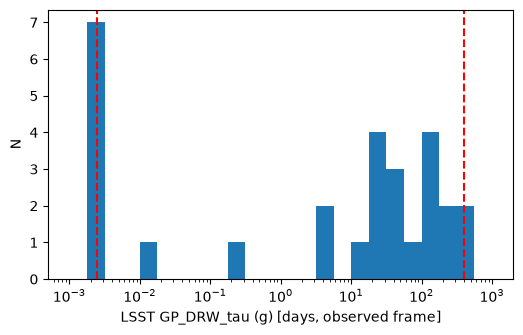

In [25]:
tau = f_lsst.GP_DRW_tau_g.dropna()
lo, hi = tau.min(), tau.max()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(tau, bins=np.logspace(-3, 3, 25))
ax.axvline(lo, color="r", ls="--")
ax.axvline(hi, color="r", ls="--")
ax.set_xscale("log")
ax.set_xlabel("LSST GP_DRW_tau (g) [days, observed frame]")
ax.set_ylabel("N")
at_bound = np.isclose(tau, lo) | np.isclose(tau, hi)
print(f"{at_bound.sum()} of {len(tau)} values sit exactly at {lo:.4f} or {hi:.1f} days")

Many τ values sit exactly at the same two numbers: these are the **limits of the fit** (0.0025 d and
$e^6 \approx 403$ d), not measurements. That is expected: LSST has observed these quasars for only a few months,
and a DRW time scale can only be measured when the light curve is much longer than τ (roughly ≥ 10 τ; Kozłowski 2017).
Compare also the two surveys for our COSMOS quasar:

In [26]:
pd.concat([am.get_features(qso_ztf, 0, FEATS, wide=True).T.rename(columns=lambda c: "ZTF"),
           am.get_features(qso_lsst, 1, FEATS, wide=True).T.rename(columns=lambda c: "LSST")], axis=1)

oid,ZTF,LSST
col,,
Amplitude_g,0.072370,0.077895
Amplitude_r,0.039632,0.058945
GP_DRW_sigma_g,18.137504,20.603730
GP_DRW_sigma_r,3.787074,10.350969
GP_DRW_tau_g,55.426734,0.002479
GP_DRW_tau_r,0.544111,0.002479
Amplitude_i,NaN,0.062021
Amplitude_u,NaN,0.059541
Amplitude_y,NaN,0.033990


The amplitudes agree, the time scales do not (and they disagree even between ZTF's g and r). **Lesson:** features
are computed automatically from whatever light curve exists at that moment; always check whether the light curve
can constrain them. To study AGN time scales we need a longer baseline: combine both surveys.

## 8. The rest-frame structure function from ZTF + LSST

A model-independent description of AGN variability is the **structure function**: the typical magnitude
difference between two epochs separated by a time lag Δt,

$$SF(\Delta t) = \sqrt{\langle(\Delta m)^2\rangle - \langle\sigma_1^2+\sigma_2^2\rangle},$$

where the second term removes the photometric noise. We measure it in the **rest frame**,
$\Delta t_{rest} = \Delta t_{obs}/(1+z)$, combining all objects with a redshift (an *ensemble* SF).

Combining surveys: ZTF and LSST filters (and calibrations) are not identical, so a ZTF–LSST pair would add a
spurious offset. We therefore only use pairs **within** each survey: LSST's dense 2026 sampling gives the short lags,
ZTF's long baseline gives the long lags. To keep it fast we first average each night.

In [27]:
def nightly(lc):
    """Average each survey/band/night (weights 1/err²)."""
    w = 1 / lc.mag_err ** 2
    lc = lc.assign(night=np.floor(lc.mjd), w=w, wt=w * lc.mjd, wm=w * lc.mag)
    s = lc.groupby(["name", "survey", "band", "night"])[["w", "wt", "wm"]].sum().reset_index()
    return s.assign(mjd=s.wt / s.w, mag=s.wm / s.w, mag_err=1 / np.sqrt(s.w))[
        ["name", "survey", "band", "mjd", "mag", "mag_err"]]


def pairs(lc, z):
    """All within-survey, within-band pairs of one object: rest-frame lag, dm², noise²."""
    rows = []
    for (survey, band), g in lc.groupby(["survey", "band"]):
        t, m, e = g.mjd.values, g.mag.values, g.mag_err.values
        i, j = np.triu_indices(len(t), k=1)
        rows.append(pd.DataFrame({"survey": survey, "band": band, "dt_rest": np.abs(t[j] - t[i]) / (1 + z),
                                  "dm2": (m[j] - m[i]) ** 2, "noise2": e[i] ** 2 + e[j] ** 2}))
    return pd.concat(rows, ignore_index=True)


lc_night = nightly(lcs[lcs.band.isin(["g", "r"])])
z_of = sample.set_index("name").z_spec
all_pairs = pd.concat([pairs(g, z_of[name]).assign(name=name)
                       for name, g in lc_night.groupby("name") if z_of.get(name, 0) > 0], ignore_index=True)
print(f"{len(all_pairs):,} pairs from {all_pairs.name.nunique()} AGN")
all_pairs.groupby("survey").dt_rest.describe().round(1)

243,978 pairs from 36 AGN


,count,mean,std,min,25%,50%,75%,max
survey,,,,,,,,
lsst,8655.0,15.8,12.7,0.2,4.6,14.4,22.9,98.6
ztf,235323.0,476.8,454.5,0.3,120.4,321.9,701.6,2276.9


power-law index gamma = 0.38
                            dt     sf      n
bin                                         
(333.833, 521.972]     424.367  0.365  32053
(521.972, 816.14]      666.044  0.410  33313
(816.14, 1276.093]     988.087  0.474  31049
(1276.093, 1995.262]  1548.337  0.363  17838


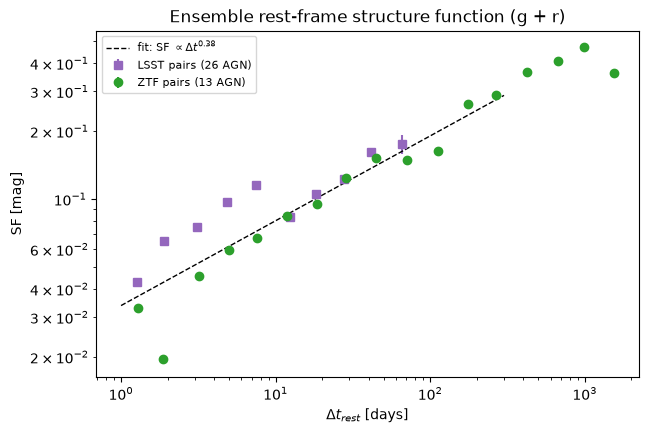

In [28]:
def structure_function(p, bins):
    p = p.assign(bin=pd.cut(p.dt_rest, bins))
    sf = p.groupby("bin", observed=True).agg(dt=("dt_rest", "median"), dm2=("dm2", "mean"),
                                             noise2=("noise2", "mean"), n=("dm2", "size"))
    sf["sf"] = np.sqrt(np.clip(sf.dm2 - sf.noise2, 0, None))
    sf["sf_err"] = sf.sf / np.sqrt(2 * sf.n)   # rough statistical error
    return sf[sf.n >= 30]


bins = np.logspace(0, 3.3, 18)
sf_by_survey = {s: structure_function(all_pairs[all_pairs.survey == s], bins) for s in ("lsst", "ztf")}
n_agn = all_pairs.groupby("survey").name.nunique()

# power-law fit SF ∝ Δt^γ over 1–300 rest-frame days, all pairs together
sf_all = structure_function(all_pairs, bins)
fit = sf_all[(sf_all.dt < 300) & (sf_all.sf > 0)]
gamma, log_a = np.polyfit(np.log10(fit.dt), np.log10(fit.sf), 1)

fig, ax = plt.subplots(figsize=(7, 4.5))
for survey, marker, color in [("lsst", "s", "tab:purple"), ("ztf", "o", "tab:green")]:
    sf = sf_by_survey[survey]
    ax.errorbar(sf.dt, sf.sf, sf.sf_err, fmt=marker, color=color, ms=6,
                label=f"{survey.upper()} pairs ({n_agn[survey]} AGN)")
x = np.logspace(0, np.log10(300), 10)
ax.plot(x, 10 ** log_a * x ** gamma, "k--", lw=1, label=rf"fit: SF $\propto \Delta t^{{{gamma:.2f}}}$")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(r"$\Delta t_{rest}$ [days]")
ax.set_ylabel("SF [mag]")
ax.set_title("Ensemble rest-frame structure function (g + r)")
ax.legend(fontsize=8)
print(f"power-law index gamma = {gamma:.2f}")
print(sf_by_survey["ztf"][["dt", "sf", "n"]].tail(4).round(3))

* The two surveys are complementary: **LSST** (dense sampling, 2026) gives lags of hours to ~100 rest-frame days,
  **ZTF** (2018–2026) extends them to ~2000 days.
* The SF rises with lag roughly as a power law (index printed above, γ ≈ 0.4): AGN vary more on longer time
  scales, as a damped random walk predicts for lags shorter than its τ.
* At lags of ~1000 days the ZTF SF reaches 0.4–0.5 mag and stops growing: a hint of the DRW "saturation" at
  lags ≳ τ, which needs years of data to see.
* At short lags the LSST points lie above the ZTF ones. The sub-samples are different (high-z quasars seen in the
  rest-frame UV vs. low-z AGN diluted by their host galaxies, and blazars), and underestimated photometric errors
  would also add a floor. Disentangling these is a nice project.

## 9. Exercises

1. **(easy)** Pick an object of the sample with `z_source == "DESI"` and open it in the experimental explorer
   (`am.explorer_url(oid, "lsst")`). Is the source point-like or extended? Is its redshift the quasar's or a host
   galaxy's?
2. **(easy)** How many objects of set A (ZTF-selected) fail the Stern et al. W1 − W2 ≥ 0.8 cut? Look at their
   ZTF light-curve class: are they blazars? (Blazars' mid-IR emission is synchrotron, and can be bluer.)
3. **(medium)** Build the rest-frame SED of another sample member with `catshtm_sed` and compare it with that of
   `ZTF20acyxpwi`. Does it have an XMM detection? If so, compute its $\alpha_{ox}$.
4. **(medium)** Recompute the structure function separately for the g and r bands. At a fixed rest-frame lag,
   which band varies more? Is this what you expect for an accretion disc?
5. **(challenge)** Fit a damped random walk, $SF(\Delta t) = SF_\infty\sqrt{1-e^{-\Delta t/\tau}}$, to the
   ensemble structure function with `scipy.optimize.curve_fit`. Compare your τ with the distribution of
   `GP_DRW_tau` from the features. Which one do you trust more, and why?

In [29]:
# your code here

**Next:** [05 · Variable stars](05_variable_stars.ipynb)